# Face Comparison using Eigenfaces

## What are Eigenfaces?

Eigenfaces are the principal components of a set of face images. The key idea is to represent each face not as a grid of raw pixel values, but as a compact set of coordinates in a lower-dimensional "face space" spanned by the most important directions of variation across all faces.

## Algorithm Steps

1. **Load & Normalise** — Load all face images, convert to grayscale, and resize to a common resolution. Flatten each image into a 1D pixel vector.

2. **Build the Data Matrix** — Stack the face vectors as columns into a matrix $F$ of shape $(\text{pixels} \times \text{faces})$.

3. **Subtract the Mean Face** — Compute the average face $\bar{f}$ across all images and subtract it from each column:
$$X = F - \bar{f}\mathbf{1}^T$$
This centres the data so we capture *variation* around the average.

4. **Singular Value Decomposition (SVD)** — Factorise the mean-subtracted matrix:
$$X = U \Sigma V^T$$
The columns of $U$ are the **eigenfaces** — orthonormal basis vectors that describe the directions of greatest variation in the face dataset.

5. **Project onto Eigenface Space** — Each face is represented by its coordinates along the eigenfaces:
$$\text{coords}_i = U^T x_i$$
where $x_i = f_i - \bar{f}$ is the mean-subtracted face.

6. **Compare Faces** — Faces that are similar will have nearby coordinates in eigenface space. We measure similarity using the **Euclidean distance** between their eigenface coordinate vectors:
$$d(i,j) = \|\text{coords}_i - \text{coords}_j\|_2$$
A smaller distance means the two faces are more alike in terms of the dominant modes of variation.

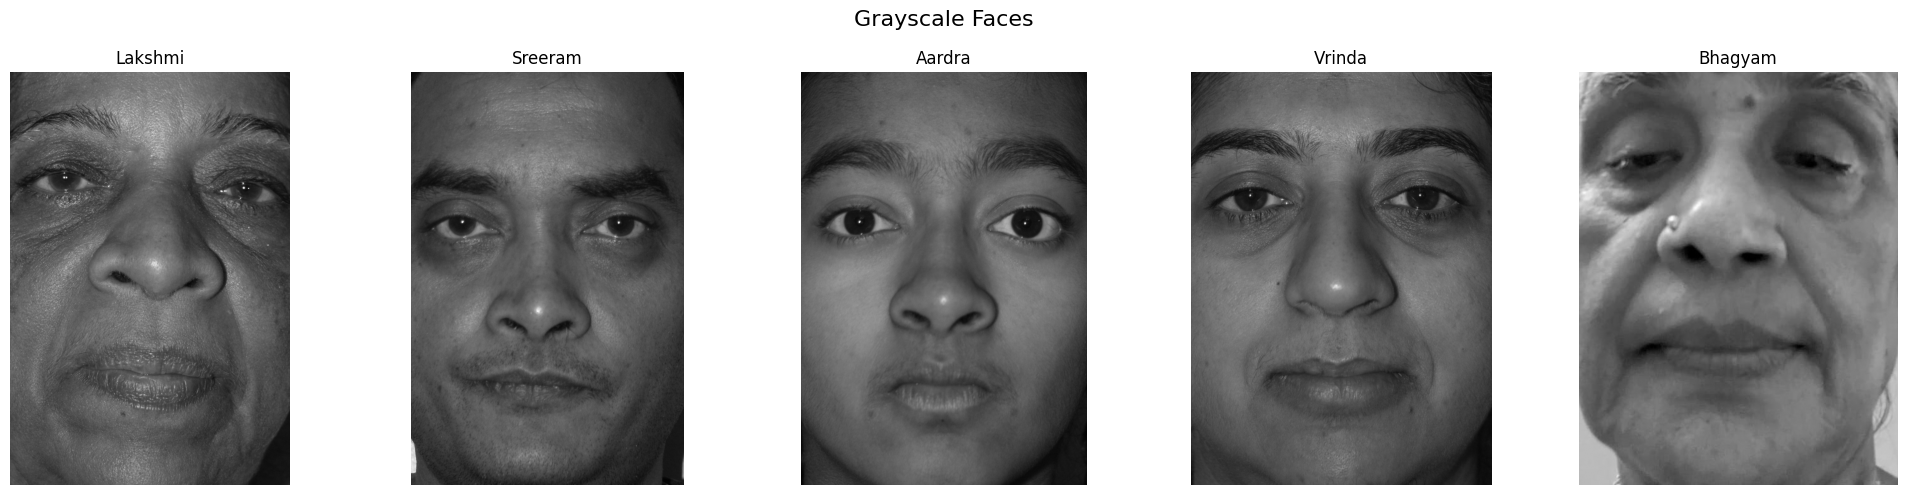

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

data_dir = '../DATA'
image_files = ['lakshmi.jpeg', 'sreeram.jpeg', 'aardra.jpeg', 'vrinda.jpeg', 'bhagyam.jpeg']
names = ['Lakshmi', 'Sreeram', 'Aardra', 'Vrinda', 'Bhagyam']

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, fname, name in zip(axes, image_files, names):
    img = Image.open(os.path.join(data_dir, fname)).convert('L')
    ax.imshow(img, cmap='gray')
    ax.set_title(name)
    ax.axis('off')

plt.suptitle('Grayscale Faces', fontsize=16)
plt.tight_layout()
plt.show()


## Eigenface-based Face Comparison

The eigenface approach works as follows:
1. Resize all face images to a common size and flatten each into a vector.
2. Stack the vectors into a matrix and subtract the mean face.
3. Compute the SVD — the left singular vectors (columns of U) are the **eigenfaces**.
4. Project each face onto the eigenface subspace (its "coordinates" in eigenface space).
5. Compare faces by their Euclidean distance in eigenface space and by visualising their projections.

Face matrix shape: (16384, 5)
U (eigenfaces) shape: (16384, 5)
Singular values: [5.25930734e+03 2.57709625e+03 2.27159501e+03 1.94474154e+03
 1.34755861e-12]


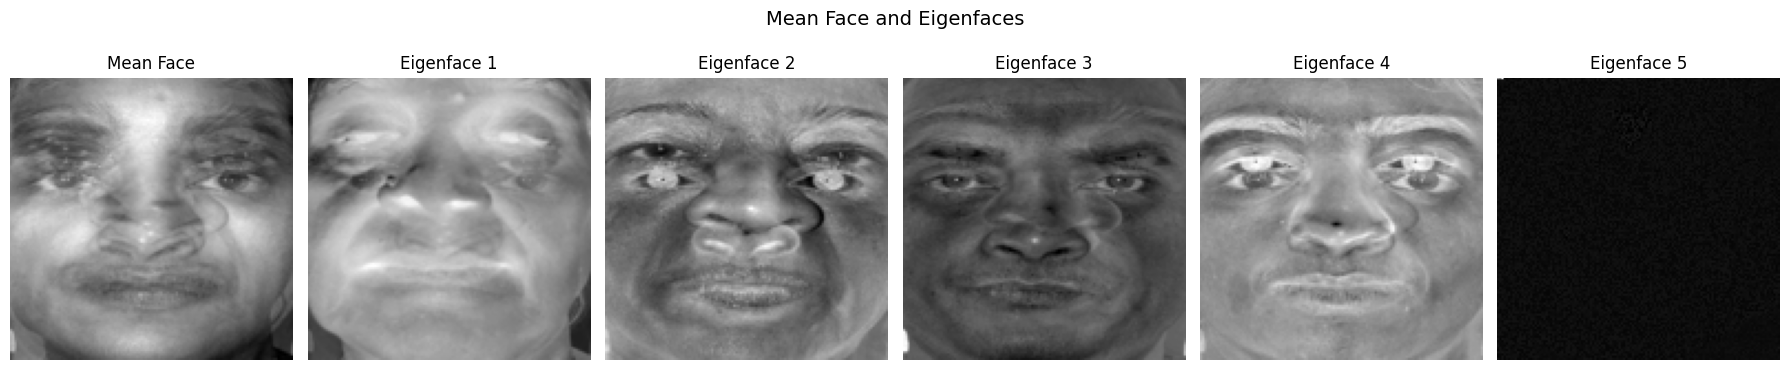

In [2]:
# Step 1: Load, resize to common size and flatten all 4 faces
TARGET_SIZE = (128, 128)  # (width, height)

face_vectors = []
for fname in image_files:
    img = Image.open(os.path.join(data_dir, fname)).convert('L').resize(TARGET_SIZE)
    face_vectors.append(np.array(img, dtype=np.float64).flatten())

# Stack as columns: shape (pixels, n_faces)
F = np.column_stack(face_vectors)   # shape (128*128, 5)
n_pixels = F.shape[0]

# Step 2: Compute mean face and subtract
avg_face = F.mean(axis=1)           # shape (n_pixels,)
F_ms = F - avg_face[:, np.newaxis]  # mean-subtracted

# Step 3: SVD → eigenfaces are columns of U
U, S, VT = np.linalg.svd(F_ms, full_matrices=False)
print(f"Face matrix shape: {F.shape}")
print(f"U (eigenfaces) shape: {U.shape}")
print(f"Singular values: {S}")

# Step 4: Show the mean face and eigenfaces
fig, axes = plt.subplots(1, 1 + U.shape[1], figsize=(18, 4))
axes[0].imshow(avg_face.reshape(TARGET_SIZE[::-1]), cmap='gray')
axes[0].set_title('Mean Face')
axes[0].axis('off')

for i in range(U.shape[1]):
    ef = U[:, i].reshape(TARGET_SIZE[::-1])
    axes[i+1].imshow(ef, cmap='gray')
    axes[i+1].set_title(f'Eigenface {i+1}')
    axes[i+1].axis('off')

plt.suptitle('Mean Face and Eigenfaces', fontsize=14)
plt.tight_layout()
plt.show()


Eigenface coordinates for each person:
  Lakshmi: [  829.81  1858.37 -1018.21   452.72    -0.  ]
  Sreeram: [1341.51  328.65 1885.91  333.54   -0.  ]
  Aardra: [ 1231.11 -1715.65  -692.83   889.03    -0.  ]
  Vrinda: [ 1287.78  -348.22  -276.39 -1635.18    -0.  ]
  Bhagyam: [-4690.21  -123.15   101.52   -40.11    -0.  ]


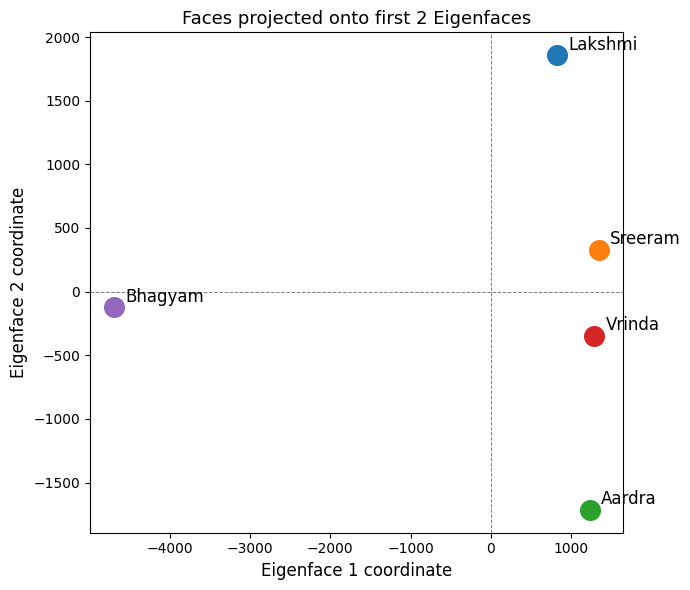

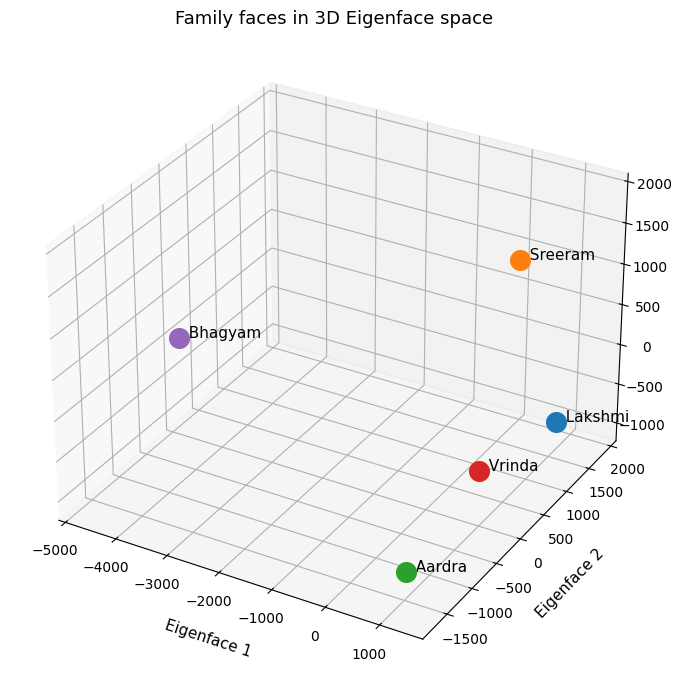


Pairwise distances in 3D eigenface space (smaller = more similar):
               Lakshmi     Sreeram      Aardra      Vrinda     Bhagyam
Lakshmi            0.0      3322.0      3611.2      2372.6      5970.8
Sreeram         3322.0         0.0      3292.6      2266.4      6306.3
Aardra          3611.2      3292.6         0.0      1430.6      6183.0
Vrinda          2372.6      2266.4      1430.6         0.0      5994.1
Bhagyam         5970.8      6306.3      6183.0      5994.1         0.0


In [3]:
from mpl_toolkits.mplot3d import Axes3D

# Step 5: Project each face onto eigenface coordinates
# coords shape: (n_eigenfaces, n_faces)
coords = U.T @ F_ms
print("Eigenface coordinates for each person:")
for i, name in enumerate(names):
    print(f"  {name}: {coords[:, i].round(2)}")

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

# Step 6a: 2D scatter — Eigenfaces 1 & 2
fig, ax = plt.subplots(figsize=(7, 6))
for i, (name, color) in enumerate(zip(names, colors)):
    ax.scatter(coords[0, i], coords[1, i], s=200, color=color, zorder=3)
    ax.annotate(name, (coords[0, i], coords[1, i]),
                textcoords='offset points', xytext=(8, 4), fontsize=12)
ax.axhline(0, color='gray', lw=0.7, ls='--')
ax.axvline(0, color='gray', lw=0.7, ls='--')
ax.set_xlabel('Eigenface 1 coordinate', fontsize=12)
ax.set_ylabel('Eigenface 2 coordinate', fontsize=12)
ax.set_title('Faces projected onto first 2 Eigenfaces', fontsize=13)
plt.tight_layout()
plt.show()

# Step 6b: 3D scatter — Eigenfaces 1, 2 & 3
fig = plt.figure(figsize=(9, 7))
ax3d = fig.add_subplot(111, projection='3d')

for i, (name, color) in enumerate(zip(names, colors)):
    ax3d.scatter(coords[0, i], coords[1, i], coords[2, i],
                 s=200, color=color, zorder=3, depthshade=True)
    ax3d.text(coords[0, i], coords[1, i], coords[2, i],
              f'  {name}', fontsize=11)

ax3d.set_xlabel('Eigenface 1', fontsize=11, labelpad=10)
ax3d.set_ylabel('Eigenface 2', fontsize=11, labelpad=10)
ax3d.set_zlabel('Eigenface 3', fontsize=11, labelpad=10)
ax3d.set_title('Family faces in 3D Eigenface space', fontsize=13)
plt.tight_layout()
plt.show()

# Step 7: Pairwise Euclidean distance using top 3 eigenfaces
print("\nPairwise distances in 3D eigenface space (smaller = more similar):")
print(f"{'':10s}", end='')
for name in names:
    print(f"{name:>12s}", end='')
print()
for i, n1 in enumerate(names):
    print(f"{n1:10s}", end='')
    for j, n2 in enumerate(names):
        dist = np.linalg.norm(coords[:3, i] - coords[:3, j])
        print(f"{dist:12.1f}", end='')
    print()
